In [ ]:
# 비지도 학습 -> y가 없다 - 2개, 3개, 4개 -> 군집 나누기 -> 학습 후 군집 나눈다 -> 예측 -> 평가? 없다
# -> 군집된 결과 -> 탐색 -> 사람이 결정 -> 라벨링(y 추가) -> new data -> 지도 학습

In [ ]:
# 실무에서는 정답없다 -> 수업에서는 적정성 평가 기준이 필요 -> 정답있는 or 정답을 사람이 구분가능한 데이터(2차원 배열 -> 의미X -> 세모/네모) 활용

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [1]:
from sklearn.datasets import load_iris  # 분류용 샘플 -> 군집인데? -> X만 사용
from sklearn.cluster import KMeans  # 거리기반 군집 알고리즘 > 변수 스케일링(표준화/정규화)
from sklearn.preprocessing import StandardScaler

In [ ]:
# 데이터 로드

iris = load_iris(as_frame=True) # X 기본값 numpy배열 로드 -> as_frame=True DataFrame으로 로드
type(iris)

sklearn.utils._bunch.Bunch

In [5]:
iris.data.head(3)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


In [7]:
iris.target.value_counts()

target
0    50
1    50
2    50
Name: count, dtype: int64

In [11]:
X = iris.data

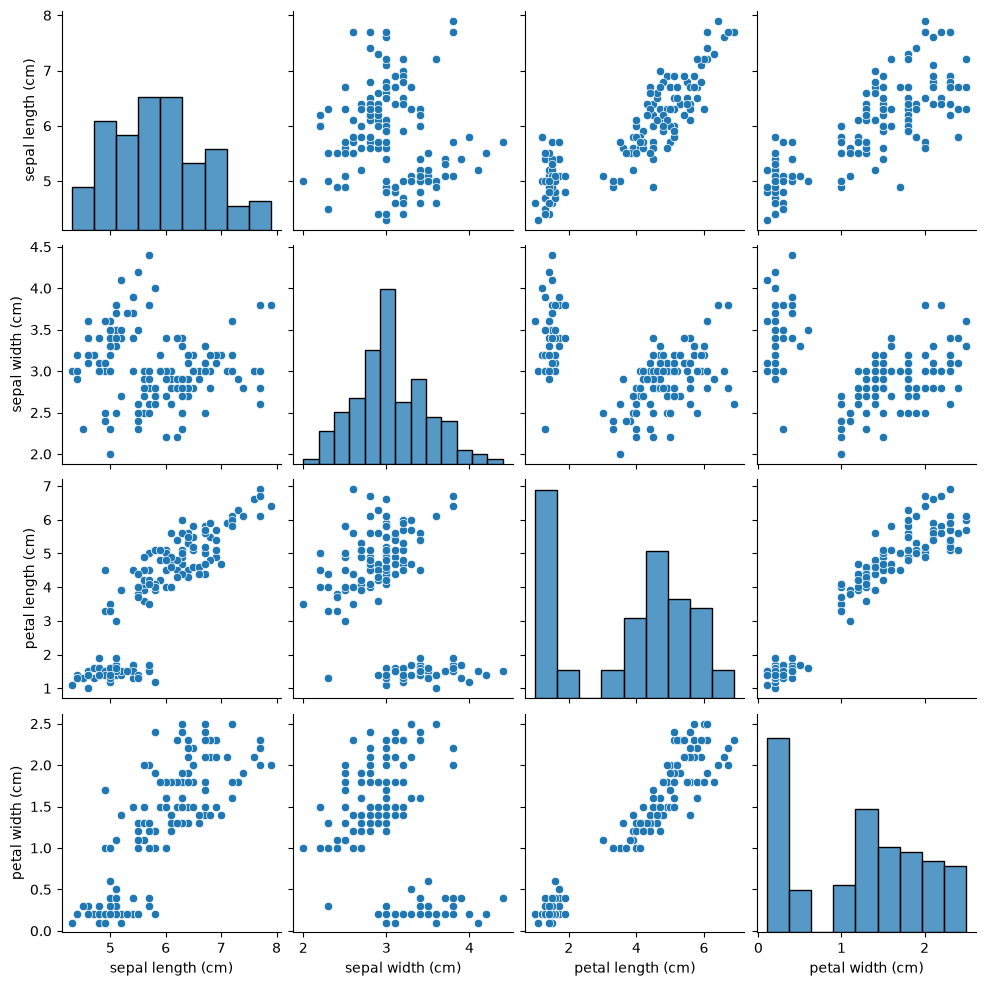

In [12]:
sns.pairplot(X)

In [15]:
scaler = StandardScaler() # X를 스케일링 -> Z-score
X_scaled = scaler.fit_transform(X)
print(X_scaled[:3])
print(X.head(3))

[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]]
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2


In [21]:
Kmeans2 = KMeans(n_clusters=2, random_state=1)
c2 = Kmeans2.fit_predict(X_scaled)  # -> 군집 0/1

Kmeans3 = KMeans(n_clusters=3, random_state=1)
c3 = Kmeans3.fit_predict(X_scaled)  # -> 군집 0/1/2

Kmeans4 = KMeans(n_clusters=4, random_state=1)
c4 = Kmeans4.fit_predict(X_scaled)  # -> 군집 0/1/2/3

In [22]:
print(c2)
print(c3)
print(c4)
print(iris.target.to_numpy())

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 1 2 2 2 0 2 0 2 0 2 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 2 2 2 2 2 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 0 2 2 2 0 2
 2 2]
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 1 3 2 2 0 2 2 2 0 2 0 0 2 0 2 0 2 2 0 0 0 2 2 2 2
 2 2 2 2 2 0 0 0 0 2 2 2 2 0 2 0 0 2 0 0 0 2 2 2 0 0 3 2 3 2 3 3 0 3 2 3 3
 2 3 2 2 3 2 3 3 0 3 2 3 2 3 3 2 2 2 3 3 3 2 2 2 3 3 2 2 3 3 3 2 3 3 3 2 2
 3 2]
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 